In [91]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [92]:
class AgentState(TypedDict):
    number1: int
    operation: str
    number2: int
    finalNumber: int

In [93]:
def add_node(state: AgentState) -> AgentState:
    """This node adds two numbers together."""
    state["finalNumber"] = state["number1"] + state["number2"]
    return state

def subtract_node(state: AgentState) -> AgentState:
    """This node subtracts two numbers."""
    state["finalNumber"] = state["number1"] - state["number2"]
    return state

def decide_next_node(state: AgentState) -> AgentState:
    """This node decides which operation to perform based on the state."""
    if state["operation"] == "+":
        return "addition_operation"
    elif state["operation"] == "-":
        return "subtraction_operation"
    else:
        raise ValueError("Invalid operation")

In [94]:
graph = StateGraph(AgentState)

graph.add_node("adder", add_node)  
graph.add_node("subtracter", subtract_node)
graph.add_node("router", lambda state: state)  # This node routes to the next operation based on the state

graph.add_edge(START, "router")

graph.add_conditional_edges(
    "router", 
    decide_next_node, 
    {
        # Edge : Node to route to based on the condition
        "addition_operation": "adder", 
        "subtraction_operation": "subtracter"
    }
)

graph.add_edge("adder", END)
graph.add_edge("subtracter", END)

app = graph.compile()

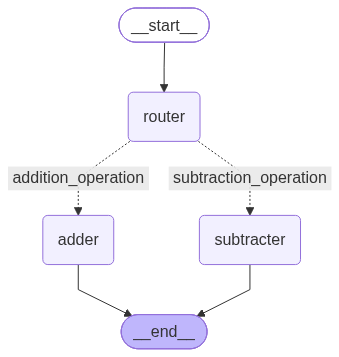

In [95]:
from IPython.display import display, Image
display(Image(app.get_graph().draw_mermaid_png()))

In [ ]:
# Output method 1: Using a dictionary for the initial state
result1 = app.invoke({
    "number1": 10,
    "operation": "+",
    "number2": 5
})
print(result1["finalNumber"])  

result2 = app.invoke({
    "number1": 10,
    "operation": "-",
    "number2": 5
})
print(result2["finalNumber"])

15
5


In [ ]:
# Output method 2: Using TypedDict for better type checking
initial_state_1 = AgentState(number1=10, operation="+", number2=5)
print (app.invoke(initial_state_1)["finalNumber"])  

initial_state_2 = AgentState(number1=10, operation="-", number2=5)
print (app.invoke(initial_state_2)["finalNumber"])  

15
5
